### Links/Utils

In [ ]:
!wget https://github.com/CMU-Perceptual-Computing-Lab/openpose/blob/master/models/getModels.sh

--2023-04-17 17:30:42--  https://github.com/CMU-Perceptual-Computing-Lab/openpose/blob/master/models/getModels.sh
Resolving github.com (github.com)... 140.82.113.4
Connecting to github.com (github.com)|140.82.113.4|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified [text/html]
Saving to: ‘getModels.sh’

getModels.sh            [ <=>                ] 161.83K  --.-KB/s    in 0.1s    

2023-04-17 17:30:43 (1.54 MB/s) - ‘getModels.sh’ saved [165711]



In [ ]:
!wget -c http://posefs1.perception.cs.cmu.edu/OpenPose/models/pose/body_25/pose_iter_584000.caffemodel -P pose/body_25/

--2023-04-17 17:30:43--  http://posefs1.perception.cs.cmu.edu/OpenPose/models/pose/body_25/pose_iter_584000.caffemodel
Resolving posefs1.perception.cs.cmu.edu (posefs1.perception.cs.cmu.edu)... 128.2.220.57
Connecting to posefs1.perception.cs.cmu.edu (posefs1.perception.cs.cmu.edu)|128.2.220.57|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 104715850 (100M) [text/plain]
Saving to: ‘pose/body_25/pose_iter_584000.caffemodel’

pose_iter_584000.ca 100%[===================>]  99.86M  27.7MB/s    in 5.3s    

2023-04-17 17:30:48 (18.8 MB/s) - ‘pose/body_25/pose_iter_584000.caffemodel’ saved [104715850/104715850]



In [ ]:
!wget http://posefs1.perception.cs.cmu.edu/OpenPose/models/pose/body_25/pose_iter_584000.caffemodel

--2023-04-17 17:30:48--  http://posefs1.perception.cs.cmu.edu/OpenPose/models/pose/body_25/pose_iter_584000.caffemodel
Resolving posefs1.perception.cs.cmu.edu (posefs1.perception.cs.cmu.edu)... 128.2.220.57
Connecting to posefs1.perception.cs.cmu.edu (posefs1.perception.cs.cmu.edu)|128.2.220.57|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 104715850 (100M) [text/plain]
Saving to: ‘pose_iter_584000.caffemodel’

pose_iter_584000.ca 100%[===================>]  99.86M  27.9MB/s    in 5.5s    

2023-04-17 17:30:54 (18.1 MB/s) - ‘pose_iter_584000.caffemodel’ saved [104715850/104715850]



In [ ]:
!wget https://github.com/CMU-Perceptual-Computing-Lab/openpose/blob/master/models/pose/body_25/pose_deploy.prototxt

--2023-04-17 17:30:54--  https://github.com/CMU-Perceptual-Computing-Lab/openpose/blob/master/models/pose/body_25/pose_deploy.prototxt
Resolving github.com (github.com)... 140.82.113.4
Connecting to github.com (github.com)|140.82.113.4|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified [text/html]
Saving to: ‘pose_deploy.prototxt’

pose_deploy.prototx     [ <=>                ] 721.38K  --.-KB/s    in 0.1s    

2023-04-17 17:30:54 (5.55 MB/s) - ‘pose_deploy.prototxt’ saved [738695]



### Constantes

In [ ]:
EPOCHS = 10
BATCH_SIZE = 8
IMG_SHAPE = (299,299)
MAX_FRAMES = 10
# Datasets PATH
DATASETS_PATH = {
  "VIOLENCE_DETECTION_DATASET_PATH": "/content/drive/MyDrive/GraduationProject/new_datasets/dataset-for-automatic-violence-detection-in-videos",
  "SURVEILLANCE_DATASET_PATH": "/content/drive/MyDrive/GraduationProject/new_datasets/fight-detection-surv-dataset",
  "PELICULAS_DATASET_PATH": "/content/drive/MyDrive/GraduationProject/new_datasets/peliculas",
  "REAL_LIFE_VIOLENCE_DATASET_PATH": "/content/drive/MyDrive/GraduationProject/new_datasets/real-life-situations-dataset",
}

### Pré Processamento

In [ ]:
import os
# from constants import MAX_FRAMES, IMG_SHAPE, DATASETS_PATH
from imutils import paths
import shutil
import pandas as pd
import numpy as np
import cv2

class Preprocessing:
  def __init__(self, dataset_path: str) -> None:
    self.dataset = None
    self.test_data = None
    self.train_data = None
    self.dataset_path = DATASETS_PATH[dataset_path]
    self.output_path = f"{self.dataset_path}/data"
    self.all_videos = None

  def crop_center_square(self, frame):
    y, x = frame.shape[0:2]
    min_dim = min(y, x)
    start_x = (x // 2) - (min_dim // 2)
    start_y = (y // 2) - (min_dim // 2)
    return frame[start_y : start_y + min_dim, start_x : start_x + min_dim]

  def load_video(self, path: str, class_subpath: str):
    temp_path = f"{self.dataset_path}/{class_subpath}/{path}"
    # print(f"video_path => {temp_path}")
    cap = cv2.VideoCapture(temp_path)
    video_frames = []

    try:
      while True:
        ret, frame = cap.read()

        if not ret:
          break

        # pick the center square from frame
        frame = self.crop_center_square(frame)

        # resize the frame for model input shape
        frame = cv2.resize(frame, IMG_SHAPE)

        # Picking the frame in RGB format
        # frame = frame[:, :, [2, 1, 0]]

        video_frames.append(frame)

        if len(video_frames) == MAX_FRAMES:
          break
    finally:
        cap.release()

    return np.array(video_frames) #, video_frames

  def prepare_dataframe(self):
    violence_videos_paths = list(paths.list_files(f"{self.dataset_path}/violence"))
    non_violence_videos_paths = list(paths.list_files(f"{self.dataset_path}/nonViolence"))

    extract_class = lambda video_name: video_name.split(self.dataset_path)[1].split("/")[1]
    extract_video_name = lambda video_name: video_name.split(self.dataset_path)[1].split("/")[2]

    self.all_videos = violence_videos_paths + non_violence_videos_paths

    self.dataset = pd.DataFrame()

    self.dataset['video_name'] = self.all_videos
    self.dataset['class'] = self.dataset['video_name'].apply(extract_class)
    self.dataset['video_name'] = self.dataset['video_name'].apply(extract_video_name)

  def move_videos(self):
    if not os.path.exists(self.output_path):
      os.mkdir(self.output_path)

    for index, item in self.dataset.iterrows():
      videoFile = item['video_name']
      videoClass = item['class']
      join_path = f"{self.dataset_path}/{videoClass}/"
      videoPath = os.path.join(join_path, videoFile)
      shutil.copy2(videoPath, self.output_path)

    print(f"\nTotal Videos: {len(os.listdir(self.output_path))}")

  def load_data(self):
    self.prepare_dataframe()
    print(self.dataset.head())
    self.move_videos()

### Treinamento

In [ ]:
import copy
import numpy as np
import pandas as pd
from datetime import date
from tensorflow.keras import utils
# from preprocessing import Preprocessing
from tensorflow.keras.metrics import Recall
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.models import Sequential
from sklearn.model_selection import train_test_split
# from constants import BATCH_SIZE, EPOCHS, MAX_FRAMES
from tensorflow.keras.callbacks import ModelCheckpoint
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.applications.xception import Xception
from tensorflow.keras.layers import TimeDistributed, Flatten, Dense, Bidirectional, LSTM, Dropout, Reshape
# from livelossplot.inputs.keras import PlotLossesCallback
# from keras_attention import Attention

class HumanViolenceDetector:
  def __init__(self) -> None:
    self.model = Sequential()
    self.preprocessing = Preprocessing(dataset_path="REAL_LIFE_VIOLENCE_DATASET_PATH")
    self.preprocessing.load_data()
    self.label_vocabulary = None

  def prepare_and_create_xception(self):
    # Create a pre-trained Xception model
    base_model = Xception(weights='imagenet', include_top=False, input_shape=(299,299,3))

    # Freeze the Xception model layers
    for layer in base_model.layers:
        layer.trainable = False

    return base_model

  def create(self) -> None:
    base_model = self.prepare_and_create_xception()
    adam = Adam(learning_rate=0.001)

    # Add a pre-trained Xception model
    self.model.add(TimeDistributed(base_model, input_shape=(MAX_FRAMES, 299, 299, 3)))
    self.model.add(TimeDistributed(Flatten()))

    # Add a Bi-LSTM layer
    self.model.add(Bidirectional(LSTM(64, return_sequences=True)))
    self.model.add(Bidirectional(LSTM(64, return_sequences=True)))

    # Add a Dropout
    self.model.add(Dropout(0.4))

    # Add a Attention layer
    # self.model.add(Attention())

    self.model.add(Dense(1024, activation="relu"))
    self.model.add(Dense(1024, activation="hard_sigmoid"))

    # Add a classification layer
    # self.model.add(Reshape((,1)))
    self.model.add(Dense(units=1, activation="sigmoid"))

    # Compile the model
    self.model.compile(loss="binary_crossentropy", optimizer=adam, metrics=["accuracy"]) # Recal()

  # TODO: Make a repeat to persist the shape (10, 299, 299, 3) in a list to train the model
  def load_frames_from_videos(self, dataframe: pd.DataFrame):
    tokenizer = Tokenizer()
    video_paths = list(dataframe["video_name"].values)
    tokenizer.fit_on_texts(dataframe["class"].values)
    labels = np.array([[token[0]-1] for token in tokenizer.texts_to_sequences(dataframe["class"].values)])
    # labels = np.array(tokenizer.texts_to_sequences(dataframe["class"].values))

    out_data = []
    out_labels = []

    for index_video_path in range(len(video_paths)):
      frames = self.preprocessing.load_video(path=video_paths[index_video_path], class_subpath=dataframe["class"].values[index_video_path])
      out_data.append(frames)
      out_labels.append(labels[index_video_path])

    return np.array(out_data), np.array(out_labels)

  def prepare_data(self):
    train_df, test_df = train_test_split(self.preprocessing.dataset, test_size = 0.30, stratify=self.preprocessing.dataset['class'])

    topNActs = train_df["class"].value_counts().nlargest(10).reset_index()["index"].tolist()
    train_new = train_df[train_df["class"].isin(topNActs)]
    test_new = test_df[test_df["class"].isin(topNActs)]

    train_new = train_new.reset_index(drop=True)
    test_new = test_new.reset_index(drop=True)

    self.preprocessing.train_data = copy.deepcopy(train_new)
    self.preprocessing.test_data = copy.deepcopy(test_new)

    self.label_vocabulary = np.unique(self.preprocessing.train_data["class"])

  def run(self, train_data: np.ndarray, train_labels: np.ndarray):
    weights_filepath = f"weights/best-weights-{str(date.today())}.h5"

    # Config callback's
    checkpoint = ModelCheckpoint(
        weights_filepath, save_weights_only=True, save_best_only=True, verbose=1
    )

    # plot_loss = PlotLossesCallback()

    # train_labels = test_labels = utils.to_categorical(self.label_vocabulary, 1)
    # print(train_data.shape, train_labels.shape)
    history = self.model.fit(
      train_data,
      train_labels,
      validation_split=0.1,
      epochs=EPOCHS,
      callbacks=[checkpoint],
      batch_size=BATCH_SIZE
    )

    return history

In [ ]:
violence_detector = HumanViolenceDetector()
violence_detector.create()
violence_detector.prepare_data()

  video_name     class
0  V_106.mp4  violence
1   V_10.mp4  violence
2  V_102.mp4  violence
3  V_101.mp4  violence
4  V_103.mp4  violence

Total Videos: 2000


#### Training Section

In [ ]:
violence_detector.model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 time_distributed_2 (TimeDis  (None, 10, 10, 10, 2048)  20861480 
 tributed)                                                       
                                                                 
 time_distributed_3 (TimeDis  (None, 10, 204800)       0         
 tributed)                                                       
                                                                 
 bidirectional_2 (Bidirectio  (None, 10, 128)          104890880 
 nal)                                                            
                                                                 
 bidirectional_3 (Bidirectio  (None, 10, 128)          98816     
 nal)                                                            
                                                                 
 dropout_1 (Dropout)         (None, 10, 128)          

In [ ]:
train_data, train_labels = violence_detector.load_frames_from_videos(dataframe=violence_detector.preprocessing.train_data)
print("\n#### Training Data ####\n")
print(f"\tdata shape: {np.array(train_data).shape}\n\tlabels shape: {np.array(train_labels).shape}\n\n")

test_out_data, test_out_labels = violence_detector.load_frames_from_videos(dataframe=violence_detector.preprocessing.test_data)
print("#### Testing Data ####\n")
print(f"\tdata shape: {np.array(test_out_data).shape}\n\tlabels shape: {np.array(test_out_labels).shape}\n\n")
# train_labels = np.asarray(train_labels).astype('float32').reshape((-1,1))
_history = violence_detector.run(train_data, train_labels)

print(f"traing history: {_history}")

### Test Section

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def img_is_color(img):

    if len(img.shape) == 3:
        # Check the color channels to see if they're all the same.
        c1, c2, c3 = img[:, : , 0], img[:, :, 1], img[:, :, 2]
        if (c1 == c2).all() and (c2 == c3).all():
            return True

    return False

def show_image_list(list_images, list_titles=None, list_cmaps=None, grid=True, num_cols=2, figsize=(20, 10), title_fontsize=30):
    '''
    Shows a grid of images, where each image is a Numpy array. The images can be either
    RGB or grayscale.

    Parameters:
    ----------
    images: list
        List of the images to be displayed.
    list_titles: list or None
        Optional list of titles to be shown for each image.
    list_cmaps: list or None
        Optional list of cmap values for each image. If None, then cmap will be
        automatically inferred.
    grid: boolean
        If True, show a grid over each image
    num_cols: int
        Number of columns to show.
    figsize: tuple of width, height
        Value to be passed to pyplot.figure()
    title_fontsize: int
        Value to be passed to set_title().
    '''

    assert isinstance(list_images, list)
    assert len(list_images) > 0
    assert isinstance(list_images[0], np.ndarray)

    if list_titles is not None:
        assert isinstance(list_titles, list)
        assert len(list_images) == len(list_titles), '%d imgs != %d titles' % (len(list_images), len(list_titles))

    if list_cmaps is not None:
        assert isinstance(list_cmaps, list)
        assert len(list_images) == len(list_cmaps), '%d imgs != %d cmaps' % (len(list_images), len(list_cmaps))

    num_images  = len(list_images)
    num_cols    = min(num_images, num_cols)
    num_rows    = int(num_images / num_cols) + (1 if num_images % num_cols != 0 else 0)

    # Create a grid of subplots.
    fig, axes = plt.subplots(num_rows, num_cols, figsize=figsize)
    
    # Create list of axes for easy iteration.
    if isinstance(axes, np.ndarray):
        list_axes = list(axes.flat)
    else:
        list_axes = [axes]

    for i in range(num_images):

        img    = list_images[i]
        title  = list_titles[i] if list_titles is not None else 'Image %d' % (i)
        cmap   = list_cmaps[i] if list_cmaps is not None else (None if img_is_color(img) else 'gray')
        
        list_axes[i].imshow(img, cmap=cmap)
        list_axes[i].set_title(title, fontsize=title_fontsize) 
        list_axes[i].grid(grid)

    for i in range(num_images, len(list_axes)):
        list_axes[i].set_visible(False)

    fig.tight_layout()
    _ = plt.show()


In [ ]:
import cv2
import numpy as np

def PM_anisotropic_diffusion(image, iterations, delta, kappa):
    # Convert the input image to grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    
    # Initialize the diffusion tensor
    D = np.ones(gray.shape, dtype=np.float32)
    
    for i in range(iterations):
        # Compute the gradient of the grayscale image
        grad = cv2.Sobel(gray, cv2.CV_32F, 1, 1)
        
        # Compute the magnitude and direction of the gradient
        mag = np.abs(grad)
        direction = np.sign(grad)
        
        # Compute the diffusion tensor
        Dxx = cv2.Sobel(D, cv2.CV_32F, 2, 0)
        Dyy = cv2.Sobel(D, cv2.CV_32F, 0, 2)
        Dxy = cv2.Sobel(D, cv2.CV_32F, 1, 1)
        D = (1 / (1 + ((mag * kappa) / delta)**2)) * \
            (D + delta**2 * (Dxx*direction[0]**2 + 2*Dxy*direction[0]*direction[1] + Dyy*direction[1]**2))
        
        # Apply the diffusion tensor to the image
        gray = gray + 0.25 * D * (cv2.Laplacian(gray, cv2.CV_32F))
    
    # Convert the output image back to color
    output = cv2.cvtColor(gray.astype(np.uint8), cv2.COLOR_GRAY2BGR)
    
    return output

### Person Detection Section

video_path => /content/drive/MyDrive/GraduationProject/new_datasets/fight-detection-surv-dataset/violence/fi003.mp4


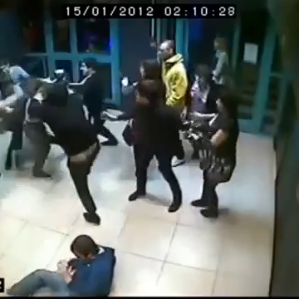

In [ ]:
pp_images = Preprocessing(dataset_path="SURVEILLANCE_DATASET_PATH")
frames = pp_images.load_video(path="fi003.mp4", class_subpath="violence")
# frames = frames + pp_images.load_video(path="fi052.mp4", class_subpath="violence")
# frames = frames + pp_images.load_video(path="fi053.mp4", class_subpath="violence")
# frames = frames + pp_images.load_video(path="fi054.mp4", class_subpath="violence")
# frames = frames + pp_images.load_video(path="fi055.mp4", class_subpath="violence")
cv2_imshow(frames[9])

In [ ]:
print(type(frames))

<class 'numpy.ndarray'>


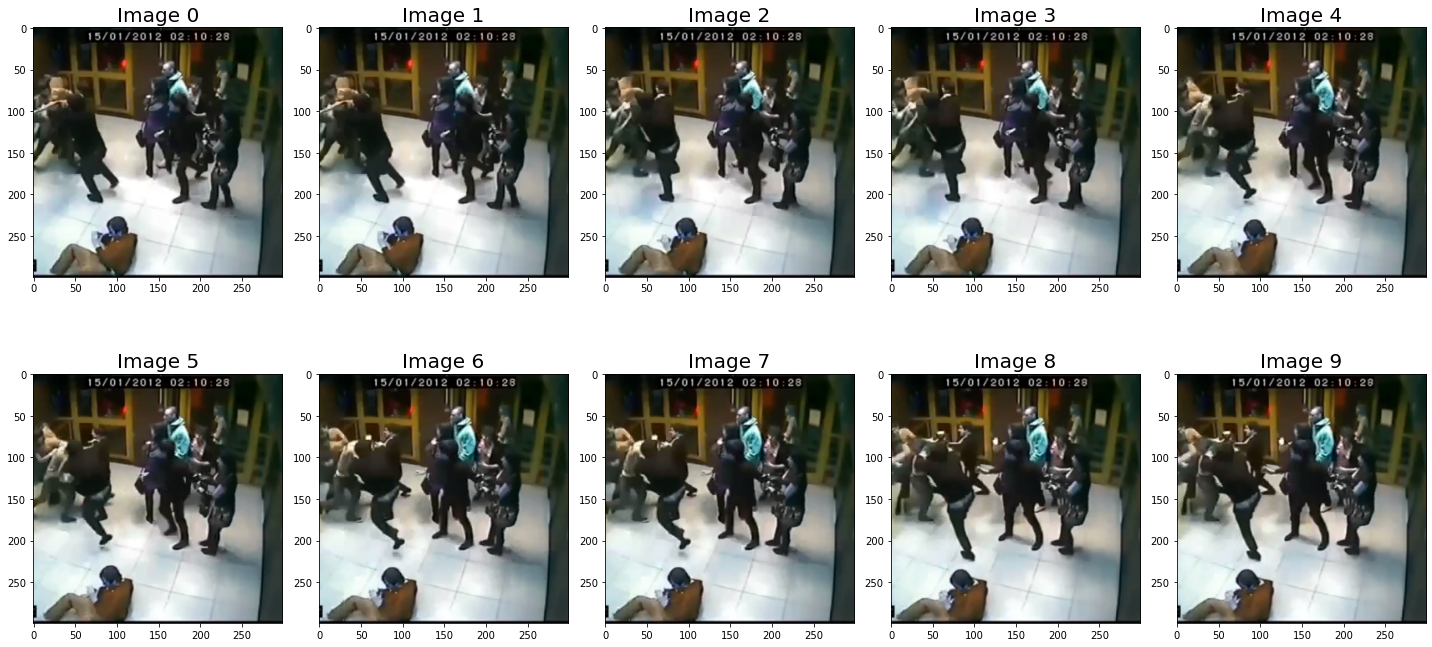

In [ ]:
show_image_list(list_images=list(frames), 
                num_cols=5,
                figsize=(20, 10),
                grid=False,
                title_fontsize=20)

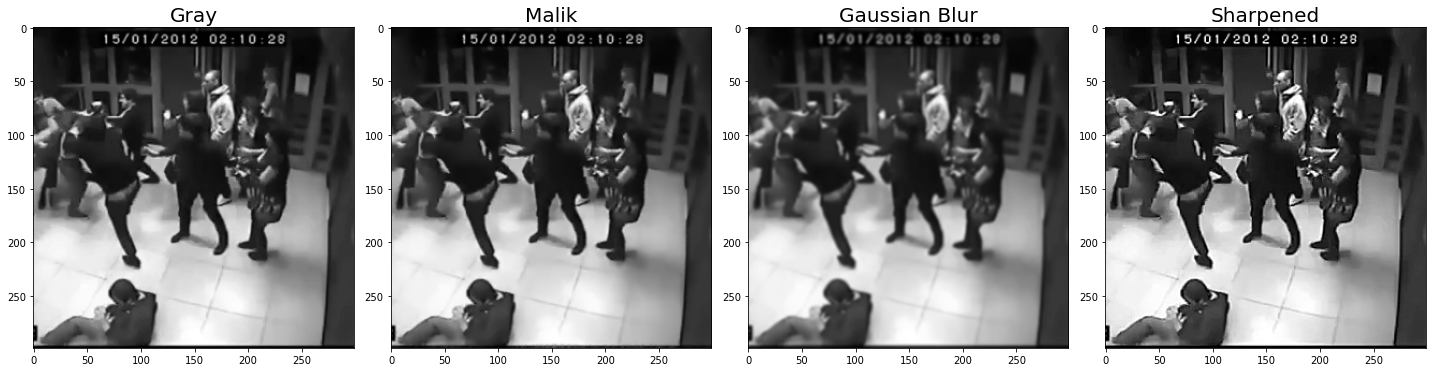

In [ ]:
gray = cv2.cvtColor(frames[9], cv2.COLOR_BGR2GRAY)
blur_pm = PM_anisotropic_diffusion(frames[9], 20, 0.20, 0.2)
blur = cv2.GaussianBlur(gray, (5, 5), 0)
unsharp = cv2.addWeighted(gray, 2.0, blur, -1.0, 1)

show_image_list(list_images=[ gray, blur_pm, blur, unsharp ], 
                list_titles=['Gray', 'Malik', 'Gaussian Blur', 'Sharpened'],
                num_cols=4,
                figsize=(20, 10),
                grid=False,
                title_fontsize=20)


In [ ]:
print(os.path.exists('/content/pose_iter_584000.caffemodel'))

True


In [ ]:
proto_file = '/content/pose_deploy.prototxt'
model_file = '/content/pose/body_25/pose_iter_584000.caffemodel'

openpose_body_25_model = cv2.dnn.readNetFromCaffe(proto_file, model_file)

error: ignored

#### Filters to enhance test

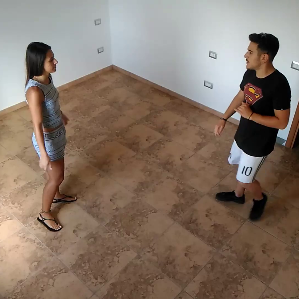

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

# Load image
# img = cv2.imread('path/to/image.jpg')
img = frames[3]

cv2_imshow(img)
# Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

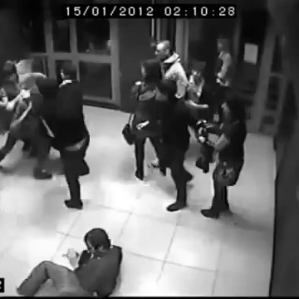

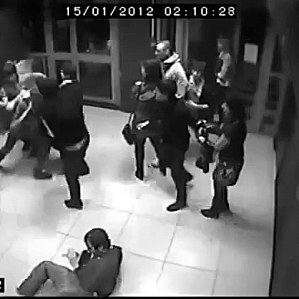

In [ ]:
# Apply Gaussian blur
blur = cv2.GaussianBlur(gray, (5, 5), 0)

# Apply unsharp masking
unsharp = cv2.addWeighted(gray, 2.0, blur, -1.0, 1)

# Display results
cv2_imshow(gray) # 'Original'
cv2_imshow(unsharp) # 'Unsharp'

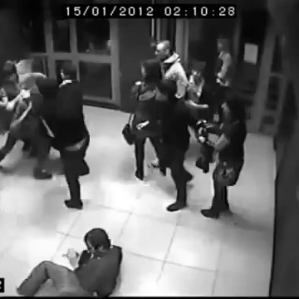

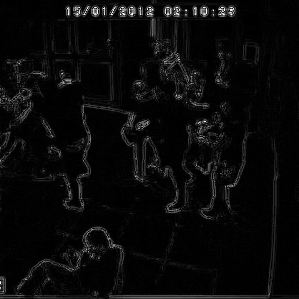

In [ ]:
# Apply the Laplacian filter to the grayscale image
laplacian = cv2.Laplacian(gray, cv2.CV_64FC4)

# Convert the Laplacian result back to uint8
sharp = cv2.convertScaleAbs(laplacian)

# Display results
cv2_imshow(gray) # 'Original'
cv2_imshow(sharp) # 'Unsharp'

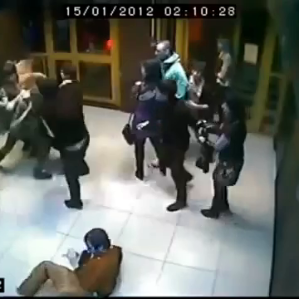

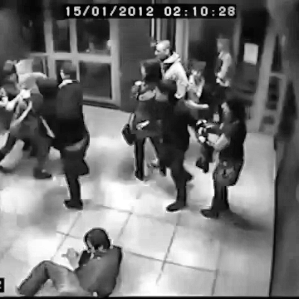

In [ ]:
# Apply contrast stretching
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
cl = clahe.apply(gray)

# Display the original and enhanced images
cv2_imshow(img) # 'Original'
cv2_imshow(cl) # 'Enhanced'

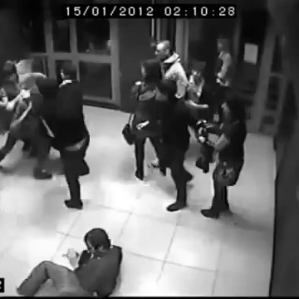

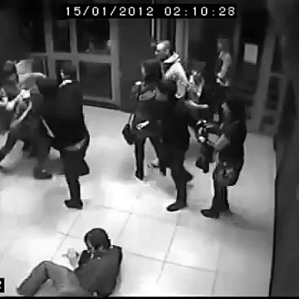

In [ ]:
# Blur the grayscale image
blur = cv2.GaussianBlur(gray, (5, 5), 0)

# Subtract the blurred image from the grayscale image
sharpened = cv2.addWeighted(gray, 1.5, blur, -0.5, 0)

# Display results
cv2_imshow(gray) # 'Original'
cv2_imshow(sharpened) # 'Unsharp'

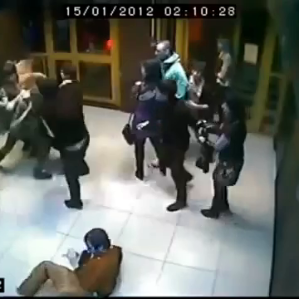

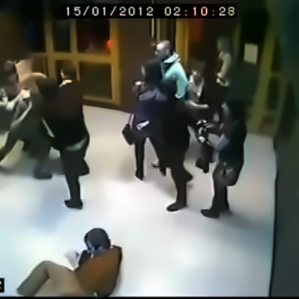

In [ ]:
# Apply Non-Local Means Denoising algorithm
denoised_img = cv2.fastNlMeansDenoisingColored(img, None, 10, 10, 7, 21)

cv2_imshow(img) # 'Original'
cv2_imshow(denoised_img) # 'Unsharp'

In [ ]:
cv2.__version__

'4.6.0'

#### Pose Estimation Tests

In [ ]:
!wget --no-check-certificate https://posefs1.perception.cs.cmu.edu/OpenPose/models/pose/coco/pose_iter_440000.caffemodel

--2023-03-21 00:50:15--  https://posefs1.perception.cs.cmu.edu/OpenPose/models/pose/coco/pose_iter_440000.caffemodel
Resolving posefs1.perception.cs.cmu.edu (posefs1.perception.cs.cmu.edu)... 128.2.220.57
Connecting to posefs1.perception.cs.cmu.edu (posefs1.perception.cs.cmu.edu)|128.2.220.57|:443... connected.
  EE certificate key too weak
HTTP request sent, awaiting response... 200 OK
Length: 209274056 (200M) [text/plain]
Saving to: ‘pose_iter_440000.caffemodel’

pose_iter_440000.ca 100%[===================>] 199.58M  32.8MB/s    in 6.7s    

2023-03-21 00:50:21 (30.0 MB/s) - ‘pose_iter_440000.caffemodel’ saved [209274056/209274056]



In [ ]:
!wget https://github.com/CMU-Perceptual-Computing-Lab/openpose/blob/master/models/pose/mpi/pose_deploy_linevec.prototxt

--2023-03-21 00:50:21--  https://github.com/CMU-Perceptual-Computing-Lab/openpose/blob/master/models/pose/mpi/pose_deploy_linevec.prototxt
Resolving github.com (github.com)... 140.82.114.4
Connecting to github.com (github.com)|140.82.114.4|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified [text/html]
Saving to: ‘pose_deploy_linevec.prototxt’

pose_deploy_linevec     [ <=>                ] 865.26K  --.-KB/s    in 0.08s   

2023-03-21 00:50:22 (11.1 MB/s) - ‘pose_deploy_linevec.prototxt’ saved [886023]



In [ ]:
net = cv2.dnn.readNetFromTensorflow('/content/pose_deploy_linevec.prototxt')

error: ignored

In [ ]:
net

In [ ]:
image = frames[9]
# Set the input blob for the network
input_blob = cv2.dnn.blobFromImage(image, 1.0 / 255, (368, 368), (0, 0, 0), swapRB=False, crop=False)
net.(input_blob)

# Forward pass through the network
output = net.forward()

# Get the number of detected people
num_people = output.shape[0] # 19
# Loop over the detected people
# for i in range(num_people):
#   # Get the keypoints for this person
#   keypoints = output[i*19:(i+1)*19,:,:]

#   # Draw the keypoints onto the image
#   image_with_keypoints = cv2.drawKeypoints(image, keypoints, outImage=None, color=(0,255,0), flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
# Get the keypoints for this person
keypoints = output[:,:,:]

# Draw the keypoints onto the image
image_with_keypoints = cv2.drawKeypoints(image, keypoints, outImage=None, color=(0,255,0), flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

AttributeError: ignored

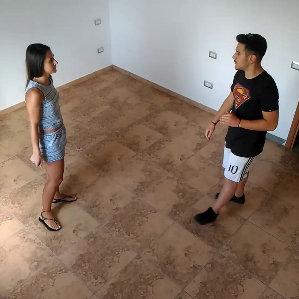

In [ ]:
# Display the image with keypoints
cv2_imshow(image_with_keypoints)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [ ]:
keypoints

array([], shape=(0, 57, 46, 46), dtype=float32)